# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.
Completed part (a) only. Numerical outputs were captured from the identical protected definitions run locally through run_a.py, not claimed as a full notebook-kernel execution. All files remain local. The figure and metrics use the unchanged official functions.


In [ ]:
import copy
import time
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)
CONFIG = dict(
    total_steps=200000,
    num_envs=4,
    num_steps=128,
    lr=0.00025,
    anneal_lr=True,
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,
)
SEEDS = [0, 1, 2, 3, 4]


# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [ ]:
class Envs:

    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = ([], [], [], [])
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r)
            terms.append(term)
            truncs.append(trunc)
            final_obs.append(fo)
        self.global_step += len(self.envs)
        return (self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs)


# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [ ]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):

    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0),
        )
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, 64)),
            nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01),
        )

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return (action, dist.log_prob(action), dist.entropy(), self.get_value(x))


# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [ ]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return (adv, adv + values)


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start : start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-08)
            pg_loss = torch.max(
                -adv * ratio, -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])
            ).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-05)
    N, T = (cfg["num_envs"], cfg["num_steps"])
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4)
    actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N)
    rewards = torch.zeros(T, N)
    dones = torch.zeros(T, N)
    values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = (next_obs, next_done)
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = (a, logp, v)
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(
                rewards,
                values,
                dones,
                agent.get_value(next_obs),
                next_done,
                cfg["gamma"],
                cfg["gae_lambda"],
            )
        b = {
            "obs": obs.reshape(-1, 4),
            "actions": actions.reshape(-1),
            "logp": logps.reshape(-1),
            "adv": adv.reshape(-1),
            "returns": returns.reshape(-1),
        }
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(
                f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  clip frac {stats['clip_frac']:.3f}"
            )
    return (agent, envs.episodes, time.time() - start)


# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [ ]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return (grid, np.array(curve))


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window : k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(
                f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  final {runs[-1]['final']:6.1f}  time {sec:5.1f} s"
            )
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {
        "name": name,
        "auc": np.mean(auc),
        "auc_std": np.std(auc),
        "steps_to_475": np.mean(st),
        "solved": sum((s < CONFIG["total_steps"] for s in st)),
        "final": np.mean(fin),
        "final_std": np.std(fin),
        "time": np.mean([r["time"] for r in runs]),
    }
    print(
        f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} ({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  time {res['time']:5.1f} s"
    )
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt

    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = (curves.mean(0), curves.std(0))
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps")
    plt.ylabel("mean return (last 10 episodes)")
    plt.legend()
    plt.show()


# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

BEGIN PPO seed=0
step  10240  mean return (last 10)   59.0  clip frac 0.000
step  20480  mean return (last 10)  150.5  clip frac 0.000
step  30720  mean return (last 10)  218.0  clip frac 0.000
step  40960  mean return (last 10)  168.2  clip frac 0.003
step  51200  mean return (last 10)  367.7  clip frac 0.000
step  61440  mean return (last 10)  390.4  clip frac 0.000
step  71680  mean return (last 10)  395.4  clip frac 0.020
step  81920  mean return (last 10)  321.7  clip frac 0.000
step  92160  mean return (last 10)  288.8  clip frac 0.001
step 102400  mean return (last 10)  277.6  clip frac 0.000
step 112640  mean return (last 10)  255.1  clip frac 0.000
step 122880  mean return (last 10)  360.3  clip frac 0.000
step 133120  mean return (last 10)  412.4  clip frac 0.000
step 143360  mean return (last 10)  320.6  clip frac 0.000
step 153600  mean return (last 10)  403.6  clip frac 0.000
step 163840  mean return (last 10)  364.8  clip frac 0.000
step 174080  mean return (last 10)  372

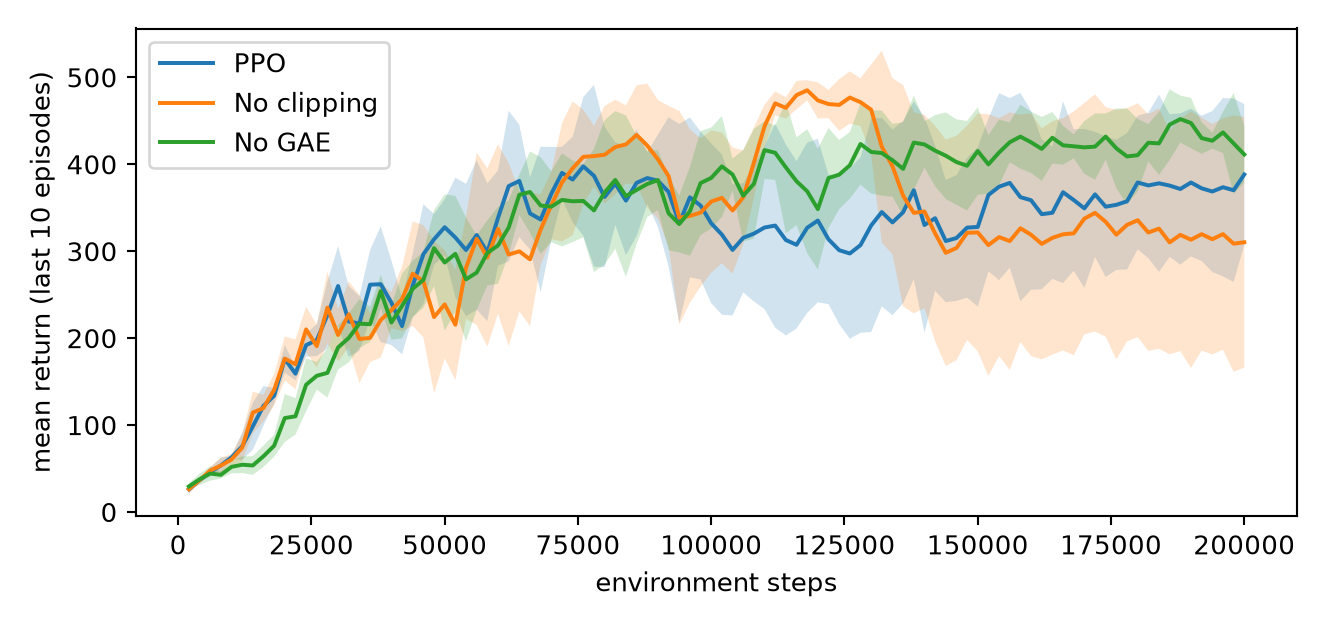

In [ ]:
all_runs = {
    "PPO": run_seeds(),
    "No clipping": run_seeds({"clip_coef": 1000000000.0}),
    "No GAE": run_seeds({"gae_lambda": 1.0}),
}
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)


## Recorded results and analysis

| Method | AUC (mean +/- SD) | Steps to 475 | Reached 475 | Final (mean +/- SD) | Train s/run |
|---|---:|---:|---:|---:|---:|
| PPO | 306.5 +/- 33.2 | 101344 | 5/5 | 482.4 +/- 27.7 | 18.4 |
| No clipping | 311.3 +/- 48.7 | 89665 | 5/5 | 367.0 +/- 141.7 | 17.0 |
| No GAE | 330.2 +/- 11.3 | 132669 | 5/5 | 497.1 +/- 3.6 | 17.4 |



**(i) Effect of clipping.** Relative to default PPO, removing clipping changes AUC by +4.9, mean steps to 475 by -11680, and final return by -115.4. No GAE has the largest AUC in these runs, while No GAE has the highest final mean. PPO's clipped surrogate limits the incentive for probability-ratio changes that are too large in a beneficial direction, making repeated updates on one rollout more conservative [1]. It is not a hard KL constraint or a guarantee of monotonic improvement. On this small task, modest updates, learning-rate annealing, advantage normalization, and gradient-norm clipping can also stabilize learning. The observed five-seed results, rather than an assumption that clipping must always win, determine the comparison.

**(ii) Effect of GAE.** Setting $\lambda=1$ changes AUC by +23.7, mean steps to 475 by +31324, and final return by +14.7. GAE combines TD residuals with weights $(\gamma\lambda)^k$. Lower $\lambda$ usually reduces variance while increasing dependence on an imperfect value function; $\lambda=1$ removes this extra decay and favors longer-horizon return estimates [2]. Here, $\lambda=1$ gives better AUC and final return but reaches 475 later. Thus the usual variance-reduction motivation does not imply that $\lambda=0.95$ must win on this task. The starter still bootstraps at rollout boundaries, so $\lambda=1$ is not completely unbootstrapped Monte Carlo. Across-seed AUC variation is also not the variance of the advantage estimator itself; these runs do not directly measure the latter.

**(iii) Does maximum performance persist?** A return of 500 is the per-episode ceiling, while the plotted training policy remains stochastic. Reaching a last-10 mean of 475 does not imply every subsequent episode has return 500, nor does a final greedy mean of 500 prove the training curve was monotonic. For example, PPO seed 1 has a later plotted last-10 return as low as 147.3 after first reaching 475; its final greedy evaluation is 483.6. The plotted declines show why a first-threshold crossing and stable retention of maximum performance are different claims. The default PPO final mean is 482.4, with SD 27.7, so the fixed evaluation also captures variation across seeds.

| Method | Seed | AUC | Steps to 475 | Final |
|---|---:|---:|---:|---:|
| PPO | 0 | 310.2 | 131337 | 500.0 |
| PPO | 1 | 278.6 | 68027 | 483.6 |
| PPO | 2 | 369.0 | 75136 | 500.0 |
| PPO | 3 | 281.6 | 74871 | 428.4 |
| PPO | 4 | 293.1 | 157351 | 500.0 |
| No clipping | 0 | 272.6 | 110306 | 229.2 |
| No clipping | 1 | 365.8 | 73773 | 500.0 |
| No clipping | 2 | 273.1 | 106469 | 440.4 |
| No clipping | 3 | 375.9 | 71489 | 500.0 |
| No clipping | 4 | 269.4 | 86287 | 165.4 |
| No GAE | 0 | 344.9 | 81763 | 492.1 |
| No GAE | 1 | 334.4 | 85229 | 493.4 |
| No GAE | 2 | 336.2 | 127425 | 500.0 |
| No GAE | 3 | 312.4 | 184687 | 500.0 |
| No GAE | 4 | 323.0 | 184239 | 500.0 |


**Validation and sources.** Protected starter definitions are checked against the original notebook's syntax trees. Saved checkpoints reproduce the official final evaluations, and the aggregate table is recomputed with the original `summarize`. The figure is created by the original `plot_curves`, with only figure size and file export handled outside it. [1] J. Schulman et al., *Proximal Policy Optimization Algorithms*, 2017, [arXiv:1707.06347](https://arxiv.org/abs/1707.06347). [2] J. Schulman et al., *High-Dimensional Continuous Control Using Generalized Advantage Estimation*, ICLR 2016, [arXiv:1506.02438](https://arxiv.org/abs/1506.02438).
